# Lab 9 — Transformer Machine Translation with OpenNMT-py
### English → Hindi · FastText word embeddings **vs.** BPEmb subword embeddings · bin-wise BLEU

In this lab you build a **Transformer** NMT system with **OpenNMT-py** on the *same data as Lab 8* (BPCC `ilci`, English → Hindi, four sentence-length bins) and compare **two kinds of pretrained embeddings** used to initialise the model.

| Step | What happens |
|---|---|
| 1 | Install / check the environment |
| 2 | Load BPCC `ilci`, make the 4 length bins, split train / valid / test (same recipe as Lab 8) |
| 3 | Background: embeddings, Transformer, BLEU (equations explained in plain words) |
| 4 | **System A** – word-level text + pretrained **FastText wiki** vectors |
| 5 | **System B** – text encoded into subwords with **BPEmb** + pretrained BPEmb vectors |
| 6 | Train an OpenNMT-py Transformer for each system (identical hyper-parameters) |
| 7 | Translate the test set and score with **sacreBLEU** — overall and **bin-wise** |
| 8 | Bin-wise result analysis + comparison of the two embeddings |

**The only thing that differs between System A and System B is the input representation** (whole words with FastText vectors vs. subword pieces with BPEmb vectors). Architecture, model size, optimiser, number of steps and test set are identical, so any BLEU difference can be attributed to the embeddings / tokenisation.

> ⏱ **Run-time warning.** Training a Transformer on a CPU is slow. Section 1 defines three profiles (`smoke`, `fast`, `standard`). Start with `smoke` once to check that everything runs (~minutes), then switch to `fast` or `standard` for real numbers.

## 1. Setup

### 1.1 Install the packages

Use `%pip` (not bare `pip`) so the packages go into **the environment this notebook's kernel is using** (your `llm_env`).

Two pins matter:

* **`pyonmttok==1.37.1`** – the 1.38.x wheels for macOS are missing `libOpenNMTTokenizer.dylib`, which makes `onmt_build_vocab` crash with `Library not loaded: @rpath/libOpenNMTTokenizer.dylib`. Version 1.37.1 ships the library correctly.
* **`numpy<2`** – OpenNMT-py 3.5.1 uses `torch 2.2`, which was built against NumPy 1.x.

If this cell changes anything, **restart the kernel** (Kernel → Restart) and run the notebook from the top.

In [1]:
# %pip install --quiet "numpy<2" "pyonmttok==1.37.1" "OpenNMT-py==3.5.1" sacrebleu sentencepiece datasets huggingface_hub bpemb gensim requests matplotlib pandas

### 1.2 Check that every library imports

If `pyonmttok` fails here, the message below tells you the exact fix.

In [2]:
import importlib

def check_import(name):
    try:
        m = importlib.import_module(name)
        print(f"  OK   {name:<12} {getattr(m, '__version__', '')}")
        return True
    except Exception as e:
        print(f"  FAIL {name:<12} {type(e).__name__}: {str(e)[:120]}")
        return False

print("Library check:")
all_ok = all([check_import(n) for n in
              ["numpy", "torch", "onmt", "pyonmttok", "sacrebleu", "sentencepiece", "gensim", "bpemb", "datasets", "requests"]])

if not all_ok:
    print("\nSomething failed to import. If it is pyonmttok, run this in a terminal (inside llm_env):")
    print('   python -m pip uninstall -y pyonmttok && python -m pip install --no-cache-dir --force-reinstall "pyonmttok==1.37.1"')
    print("then restart the kernel.")
else:
    print("\nAll libraries available.")

Library check:
  OK   numpy        1.26.4
  OK   torch        2.2.2
  OK   onmt         3.5.1
  OK   pyonmttok    1.37.1
  OK   sacrebleu    2.6.0
  OK   sentencepiece 0.2.2
  OK   gensim       4.4.0
  OK   bpemb        
  OK   datasets     5.0.1
  OK   requests     2.34.2

All libraries available.


### 1.3 Configuration (the only cell you normally edit)

| Setting | Meaning |
|---|---|
| `DATA_SOURCE` | `"bpcc"` = the real dataset (default). `"demo"` = a tiny synthetic set, only to test that the code runs. |
| `PROFILE` | `"smoke"` (≈40 training steps – just a plumbing test), `"fast"` (1 500 steps), `"standard"` (5 000 steps). |
| `D_MODEL`, `HEADS` | Transformer width. **`D_MODEL` must equal the embedding size (300)** because the pretrained vectors are 300-dimensional and OpenNMT-py uses the same size for embeddings and hidden states. `HEADS` must divide 300 (6 → 50 dimensions per head). |
| `FT_MAX_WORDS` | How many of the most frequent FastText words to keep (the full English file is ~6 GB; the top 200 k words cover almost everything we need). |
| `BPE_VS` | BPEmb subword vocabulary size (10 000 pieces per language). |

The `os.environ.get(...)` lines just let you override a setting without editing the notebook; leave them as they are.

In [3]:
import os, re, sys, json, time, random, shutil, subprocess, unicodedata, collections, csv
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sacrebleu
from sacrebleu.metrics import BLEU, CHRF

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# ---- languages -------------------------------------------------------------
SRC_LANG, TGT_LANG = "eng_Latn", "hin_Deva"   # BPCC language codes
SRC_WIKI, TGT_WIKI = "en", "hi"               # codes used by fastText-wiki and BPEmb

# ---- what to run -----------------------------------------------------------
DATA_SOURCE = os.environ.get("LAB9_DATA", "bpcc")          # "bpcc" or "demo"
PROFILE     = os.environ.get("LAB9_PROFILE", "standard")   # "smoke" | "fast" | "standard"

PROFILES = {
    #            training steps / validate every / LR warm-up / enc+dec layers / FFN size / tokens per batch / cap on #train pairs
    "smoke":    dict(train_steps=40,   valid_steps=40,   warmup=20,  layers=1, ff=512,  batch_tokens=512,  max_train=None),
    "fast":     dict(train_steps=1500, valid_steps=500,  warmup=400, layers=2, ff=1024, batch_tokens=2048, max_train=30000),
    "standard": dict(train_steps=5000, valid_steps=1000, warmup=800, layers=3, ff=1200, batch_tokens=3072, max_train=None),
}
P = PROFILES[PROFILE]

# ---- model (identical for both systems) -----------------------------------
D_MODEL = 300          # = embedding size = hidden size
HEADS   = 6            # 300 / 6 = 50 dims per head
DROPOUT = 0.2
assert D_MODEL % HEADS == 0

# ---- embeddings ------------------------------------------------------------
FT_MAX_WORDS = 200_000   # keep the top-N most frequent words of each fastText wiki file
FT_VOCAB     = 32_000    # NMT vocabulary size for the word-level system
BPE_VS, BPE_DIM = 10_000, 300

# ---- folders ---------------------------------------------------------------
WORK_DIR = "nmt_lab9"
EMB_DIR  = f"{WORK_DIR}/emb"
FT_DIR   = f"{WORK_DIR}/ft"       # System A files
BPE_DIR  = f"{WORK_DIR}/bpe"      # System B files
for d in (WORK_DIR, EMB_DIR, FT_DIR, BPE_DIR):
    os.makedirs(d, exist_ok=True)

FORCE_RETRAIN = False    # True = ignore an existing trained model and train again

print(f"DATA_SOURCE = {DATA_SOURCE}   PROFILE = {PROFILE}")
print("Profile settings:", P)

DATA_SOURCE = bpcc   PROFILE = standard
Profile settings: {'train_steps': 5000, 'valid_steps': 1000, 'warmup': 800, 'layers': 3, 'ff': 1200, 'batch_tokens': 3072, 'max_train': None}


## 2. Data — BPCC `ilci`, English → Hindi, four length bins

This is the **same dataset and the same recipe as Lab 8**:

* source = English, target = Hindi,
* every sentence pair is put in one of four **bins** according to the number of **English words**:

| bin | English words |
|---|---|
| bin1 | ≤ 10 |
| bin2 | 11 – 20 |
| bin3 | 21 – 30 |
| bin4 | > 30 |

* 10 % of each bin is held out as the **test set** (so every bin is represented in the test set), the rest is training data. A small validation slice (5 %) of the training data is used by OpenNMT-py during training.

### 2.1 Loading BPCC

`ai4bharat/BPCC` is a **gated** dataset on HuggingFace. One-time set-up (takes 2 minutes):

1. Open <https://huggingface.co/datasets/ai4bharat/BPCC> while logged in and click **Agree / Access repository**.
2. Create a read token at <https://huggingface.co/settings/tokens>.
3. In a terminal (inside `llm_env`) run `huggingface-cli login` and paste the token — or set the environment variable `HF_TOKEN` before starting Jupyter.

The repository contains one TSV file per language in the `ilci/` folder (`ilci/hin_Deva.tsv`, …). The loader below tries the `datasets` library first and falls back to downloading that TSV directly. It decides which column is English and which is Hindi **by script (Latin vs. Devanagari)**, not by trusting a column name.

> If loading fails, the notebook **stops with a clear message** instead of silently switching to toy data (that is what happened in Lab 8).

In [4]:
# <YOUR_HUGGINGFACE_TOKEN_HERE>
from getpass import getpass
from huggingface_hub import login, whoami

login(token=getpass("Paste your HuggingFace READ token and press Enter: "))
print("Logged in as:", whoami()["name"])

Logged in as: GADAAR


In [5]:
def _ascii_ratio(texts):
    """Share of alphabetic characters that are plain ASCII (high = English, low = Devanagari)."""
    letters = [ch for t in texts for ch in t if ch.isalpha()]
    return sum(ch.isascii() for ch in letters) / max(1, len(letters))

def _frame_to_pairs(df, col_en=None, col_hi=None):
    """Turn a DataFrame with two text columns into (english, hindi) pairs."""
    cols = [str(c) for c in df.columns]
    if col_en and col_hi:
        a, b = df[col_en], df[col_hi]
    elif "src" in cols and "tgt" in cols:
        a, b = df["src"], df["tgt"]
    else:
        en_like = [c for c in cols if "eng" in c.lower()]
        hi_like = [c for c in cols if "hin" in c.lower()]
        if en_like and hi_like:
            a, b = df[en_like[0]], df[hi_like[0]]
        else:
            raise ValueError(f"Cannot tell which columns hold the text. Columns found: {cols}. "
                             f"Set col_en / col_hi explicitly in load_bpcc_ilci(...).")
    a = a.astype(str).str.strip().tolist()
    b = b.astype(str).str.strip().tolist()
    # decide orientation by script, so the result is always (English, Hindi)
    if _ascii_ratio(a[:300]) < _ascii_ratio(b[:300]):
        a, b = b, a
    return [(x, y) for x, y in zip(a, b) if x and y and x.lower() != "nan" and y.lower() != "nan"]

def load_bpcc_ilci(tgt_lang="hin_Deva", col_en=None, col_hi=None):
    """Load BPCC ilci (English <-> tgt_lang). Raises RuntimeError with instructions on failure."""
    errors = []

    # Path A: HuggingFace `datasets` (config 'ilci', one split per language)
    try:
        from datasets import load_dataset
        ds = load_dataset("ai4bharat/BPCC", "ilci", split=tgt_lang)
        pairs = _frame_to_pairs(ds.to_pandas(), col_en, col_hi)
        if pairs:
            return pairs
        errors.append("datasets: loaded but produced 0 pairs")
    except Exception as e:
        errors.append(f"datasets.load_dataset -> {type(e).__name__}: {str(e)[:300]}")

    # Path B: download ilci/<lang>.tsv directly from the dataset repo
    try:
        from huggingface_hub import hf_hub_download
        path = hf_hub_download("ai4bharat/BPCC", f"ilci/{tgt_lang}.tsv", repo_type="dataset")
        df = pd.read_csv(path, sep="\t", quoting=csv.QUOTE_NONE, dtype=str,
                         keep_default_na=False, on_bad_lines="skip")
        pairs = _frame_to_pairs(df, col_en, col_hi)
        if pairs:
            return pairs
        errors.append("hf_hub_download: file read but produced 0 pairs")
    except Exception as e:
        errors.append(f"hf_hub_download -> {type(e).__name__}: {str(e)[:300]}")

    raise RuntimeError(
        "Could not load BPCC ilci.\n  - " + "\n  - ".join(errors) + "\n\n"
        "Most likely fix: accept the dataset terms at https://huggingface.co/datasets/ai4bharat/BPCC , "
        "then run `huggingface-cli login` (or set HF_TOKEN) and re-run this cell.\n"
        "To only test the code with toy data, set DATA_SOURCE = 'demo' in the configuration cell."
    )

In [7]:
def build_demo_parallel_data():
    """Small synthetic English-Hindi pairs spanning all 4 length bins. NOT real data --
    only used to check that the pipeline runs (DATA_SOURCE = 'demo')."""
    short_pairs = [
        ("The cat sat on the mat.", "बिल्ली चटाई पर बैठी।"),
        ("She went to the market.", "वह बाज़ार गई।"),
        ("This book is interesting.", "यह किताब दिलचस्प है।"),
        ("He plays football daily.", "वह रोज़ फुटबॉल खेलता है।"),
        ("The train is late today.", "ट्रेन आज देर से है।"),
        ("I would like some tea.", "मुझे कुछ चाय चाहिए।"),
        ("The weather is very pleasant.", "मौसम बहुत सुहावना है।"),
        ("They live near the river.", "वे नदी के पास रहते हैं।"),
    ]
    medium_pairs = [
        ("The company declined to comment on the matter raised by reporters.",
         "कंपनी ने पत्रकारों द्वारा उठाए गए मामले पर टिप्पणी करने से इनकार कर दिया।"),
        ("Doctors recommend regular exercise and a balanced diet for good health.",
         "डॉक्टर अच्छे स्वास्थ्य के लिए नियमित व्यायाम और संतुलित आहार की सलाह देते हैं।"),
        ("The government announced a new policy to support small businesses.",
         "सरकार ने छोटे व्यवसायों का समर्थन करने के लिए एक नई नीति की घोषणा की।"),
        ("Tourists visiting the region should carry warm clothes and sturdy shoes.",
         "इस क्षेत्र में आने वाले पर्यटकों को गर्म कपड़े और मजबूत जूते साथ रखने चाहिए।"),
        ("The hospital has introduced a new system to reduce patient waiting times.",
         "अस्पताल ने मरीजों के प्रतीक्षा समय को कम करने के लिए एक नई प्रणाली शुरू की है।"),
        ("Farmers in the area have faced difficulties due to the unexpected rainfall.",
         "इस क्षेत्र के किसानों को अप्रत्याशित बारिश के कारण कठिनाइयों का सामना करना पड़ा है।"),
    ]
    long_pairs = [
        ("The committee, after reviewing the proposal in detail over several meetings, "
         "decided to approve the project but requested additional safety measures.",
         "समिति ने कई बैठकों में प्रस्ताव की विस्तार से समीक्षा करने के बाद, परियोजना को मंजूरी देने "
         "का निर्णय लिया लेकिन अतिरिक्त सुरक्षा उपायों का अनुरोध किया।"),
        ("Researchers have found that regular physical activity, combined with a healthy diet "
         "and adequate sleep, significantly reduces the risk of several chronic diseases.",
         "शोधकर्ताओं ने पाया है कि नियमित शारीरिक गतिविधि, स्वस्थ आहार और पर्याप्त नींद के साथ मिलकर, "
         "कई पुरानी बीमारियों के खतरे को काफी हद तक कम करती है।"),
        ("The annual conference, which brings together experts from across the country to "
         "discuss emerging trends in technology, education, and public policy, will be held "
         "next month in the capital.",
         "वार्षिक सम्मेलन, जो प्रौद्योगिकी, शिक्षा और सार्वजनिक नीति में उभरते रुझानों पर चर्चा करने के "
         "लिए देशभर के विशेषज्ञों को एक साथ लाता है, अगले महीने राजधानी में आयोजित किया जाएगा।"),
        ("Despite facing numerous challenges during the construction of the bridge, including "
         "unexpected delays due to weather conditions and material shortages, the engineering "
         "team managed to complete the project ahead of the revised deadline.",
         "पुल के निर्माण के दौरान कई चुनौतियों का सामना करने के बावजूद, जिसमें मौसम की स्थिति और "
         "सामग्री की कमी के कारण अप्रत्याशित देरी शामिल थी, इंजीनियरिंग टीम ने संशोधित समय सीमा से "
         "पहले ही परियोजना को पूरा करने में सफलता हासिल की।"),
    ]
    all_pairs = (short_pairs * 15) + (medium_pairs * 15) + (long_pairs * 15)
    random.Random(RANDOM_SEED).shuffle(all_pairs)
    return all_pairs

if DATA_SOURCE == "bpcc":
    parallel_pairs = load_bpcc_ilci(TGT_LANG)          # raises a clear error if it cannot load
    print(f"Loaded {len(parallel_pairs):,} real BPCC ilci English-Hindi pairs.")
else:
    print("=" * 78)
    print("DEMO MODE: using a tiny synthetic dataset. Results are NOT meaningful.")
    print("=" * 78)
    parallel_pairs = build_demo_parallel_data()

print("Example pair:")
print("  EN:", parallel_pairs[0][0])
print("  HI:", parallel_pairs[0][1])

ilci/asm_Beng.tsv: reconstructing file:   0%|          |  0.00B / 27.8MB            

ilci/asm_Beng.tsv: downloading bytes:           |  0.00B            

ilci/ben_Beng.tsv: reconstructing file:   0%|          |  0.00B / 45.3MB            

ilci/ben_Beng.tsv: downloading bytes:           |  0.00B            

ilci/brx_Deva.tsv: reconstructing file:   0%|          |  0.00B / 33.4MB            

ilci/brx_Deva.tsv: downloading bytes:           |  0.00B            

... (39 outputs left out)

Generating tam_Taml split: 0 examples [00:00, ? examples/s]

Generating tel_Telu split: 0 examples [00:00, ? examples/s]

Generating urd_Arab split: 0 examples [00:00, ? examples/s]

Loaded 165,649 real BPCC ilci English-Hindi pairs.
Example pair:
  EN: Some countries have declining epidemics, with no reported case in weeks.
  HI: कुछ देशों में महामारी घटती जा रही है, जहाँ कई हफ्तों से कोई मामला नहीं है।


### 2.2 Length bins and train / valid / test split

`assign_bin` counts **English words** (whitespace-separated) and returns the bin name. Then, **inside each bin separately**, 10 % of the pairs are moved to the test set (`test_bin_of` remembers each test sentence's bin so we can compute BLEU per bin later).

> **Small improvement over Lab 8:** after the test set is taken out, the remaining training pairs are **shuffled across bins** before the validation slice is cut off. (In Lab 8 the pairs were still ordered bin by bin, so the validation slice came only from bin1.) The **test set is exactly the same as in Lab 8** because it is chosen with the same seed and the same procedure.

In [8]:
BIN_ORDER = ["bin1 (<=10)", "bin2 (10,20]", "bin3 (20,30]", "bin4 (>30)"]

def assign_bin(src_text):
    n = len(src_text.split())
    if n <= 10:
        return "bin1 (<=10)"
    elif n <= 20:
        return "bin2 (10,20]"
    elif n <= 30:
        return "bin3 (20,30]"
    return "bin4 (>30)"

binned = defaultdict(list)
for src, tgt in parallel_pairs:
    binned[assign_bin(src)].append((src, tgt))

print(f"{'bin':<15}{'pairs':>10}")
for b in BIN_ORDER:
    print(f"{b:<15}{len(binned[b]):>10,}")

bin                 pairs
bin1 (<=10)        33,374
bin2 (10,20]       75,584
bin3 (20,30]       39,004
bin4 (>30)         17,687


In [9]:
TEST_FRACTION = 0.10   # taken from every bin

train_pairs, test_pairs, test_bin_of = [], [], []
rng = random.Random(RANDOM_SEED)
for b in BIN_ORDER:
    items = binned[b][:]
    rng.shuffle(items)
    n_test = max(1, int(len(items) * TEST_FRACTION)) if items else 0
    test_pairs.extend(items[:n_test])
    test_bin_of.extend([b] * n_test)
    train_pairs.extend(items[n_test:])

# shuffle the pooled training data (so validation / any size cap draws from ALL bins)
random.Random(RANDOM_SEED + 1).shuffle(train_pairs)
n_valid = max(1, int(len(train_pairs) * 0.05))
valid_pairs     = train_pairs[:n_valid]
fit_train_pairs = train_pairs[n_valid:]
if P["max_train"]:
    fit_train_pairs = fit_train_pairs[:P["max_train"]]

print(f"train = {len(fit_train_pairs):,}   valid = {len(valid_pairs):,}   test = {len(test_pairs):,}")
print("\nTest sentences per bin:")
for b in BIN_ORDER:
    print(f"  {b:<15}{test_bin_of.count(b):>7,}")

# quick data-quality check: how many test sources also occur in training? (leakage inflates BLEU)
train_src_set = {s for s, _ in fit_train_pairs}
overlap = sum(1 for s, _ in test_pairs if s in train_src_set)
print(f"\nTest sources that also appear verbatim in training data: {overlap:,} ({100*overlap/len(test_pairs):.1f}%)")

train = 141,632   valid = 7,454   test = 16,563

Test sentences per bin:
  bin1 (<=10)      3,337
  bin2 (10,20]     7,558
  bin3 (20,30]     3,900
  bin4 (>30)       1,768

Test sources that also appear verbatim in training data: 671 (4.1%)


## 3. Background — what is inside the model?

### 3.1 Word and subword embeddings

A neural network cannot read text, only numbers. An **embedding table** $E\in\mathbb{R}^{|V|\times d}$ gives every vocabulary item $x_i$ a $d$-dimensional vector:

$$ e_i = E[x_i] \qquad\text{(a row lookup)} $$

OpenNMT-py's Transformer additionally scales the embeddings by $\sqrt d$ before adding position information:

$$ z_i = \sqrt{d}\cdot e_i + PE_i $$

(The scaling keeps the embedding the same size as the positional signal.) **Pretrained embeddings** simply fill $E$ with vectors learned beforehand on huge text, so the model starts with a sensible notion of "similar words" instead of random noise. We still **fine-tune** them during NMT training.

| | System A: **FastText wiki** | System B: **BPEmb** |
|---|---|---|
| Unit | whole **words** (after splitting punctuation) | **BPE subword pieces** (e.g. `▁trans`, `lation`) |
| Vectors trained on | Wikipedia with the fastText skip-gram model (character n-grams inside) | Wikipedia segmented into BPE pieces, vectors trained with GloVe |
| Dimension | 300 | 300 (we choose `dim=300`) |
| Vocabulary | up to ~32 000 training words; rare words become `<unk>` | 10 000 pieces; **no unknown words** – any word can be spelled with pieces |
| Sequence length | short (1 token per word) | longer (≈1.3–2 pieces per word) |

**Words missing from the embedding file** get an all-zero vector in OpenNMT-py (this also holds for the special tokens `<blank> <s> </s> <unk>`). That is fine because we do not freeze the embeddings — training moves them away from zero.

**FastText skip-gram idea.** A word $w$ is represented by its character n-grams $G_w$ (e.g. `where` → `<wh, whe, her, ere, re>` and the word itself). The score of word $w$ with context word $c$ is

$$ s(w,c)=\sum_{g\in G_w} \mathbf z_g^{\top}\,\mathbf v_c $$

so related word forms (*play, played, playing*) share n-gram vectors. The `wiki.*.vec` files store the final **word** vectors.

**BPE (byte-pair encoding).** Start from characters; repeatedly merge the most frequent adjacent pair of symbols into a new symbol. After ~10 000 merges frequent words are single pieces, rare words are split into pieces. `▁` marks "this piece starts a new word", which makes decoding lossless.

### 3.2 The Transformer in five equations

1. **Positional encoding** (no recurrence, so position must be injected):
$$ PE_{(pos,2i)}=\sin\!\Big(\frac{pos}{10000^{2i/d}}\Big),\qquad PE_{(pos,2i+1)}=\cos\!\Big(\frac{pos}{10000^{2i/d}}\Big) $$

2. **Scaled dot-product attention** — each position asks a *query* $Q$, compares it with all *keys* $K$, and mixes the *values* $V$ with the resulting weights:
$$ \text{Attention}(Q,K,V)=\text{softmax}\!\Big(\frac{QK^{\top}}{\sqrt{d_k}}\Big)V $$
Dividing by $\sqrt{d_k}$ stops the dot products from growing with the dimension (which would saturate the softmax).

3. **Multi-head attention** — $h$ attention "views" in parallel ($h=6$, $d_k=300/6=50$):
$$ \text{MultiHead}(Q,K,V)=\text{Concat}(\text{head}_1,\dots,\text{head}_h)W^O,\quad \text{head}_j=\text{Attention}(QW^Q_j,KW^K_j,VW^V_j) $$

4. **Position-wise feed-forward network** applied to every position:
$$ \text{FFN}(x)=\max(0,\;xW_1+b_1)W_2+b_2 $$
Each sub-layer is wrapped with a residual connection and layer norm: $x\leftarrow x+\text{Sublayer}(\text{LayerNorm}(x))$.

5. **Training loss with label smoothing** ($\varepsilon=0.1$) — the target distribution keeps $1-\varepsilon$ on the correct word and spreads $\varepsilon$ over the others, which reduces over-confidence:
$$ \mathcal L=-\sum_t\sum_{v\in V}q(v)\,\log p_\theta(v\mid y_{<t},x),\qquad q(v)=\begin{cases}1-\varepsilon & v=y_t\\ \varepsilon/(|V|-1)&\text{otherwise}\end{cases} $$

**Learning rate ("Noam" schedule)** — rises linearly for `warmup` steps, then decays like $1/\sqrt{\text{step}}$:
$$ lr = \text{factor}\cdot d^{-0.5}\cdot\min\!\big(\text{step}^{-0.5},\;\text{step}\cdot \text{warmup}^{-1.5}\big) $$

**Decoding** uses **beam search** (width 5): at every step keep the 5 most probable partial translations.

### 3.3 BLEU in one paragraph

BLEU compares the system output with the reference through **modified n-gram precisions** $p_n$ (n = 1…4; an n-gram is counted at most as often as it appears in the reference) and multiplies by a **brevity penalty** that punishes outputs shorter than the reference:

$$ \text{BLEU}=BP\cdot\exp\Big(\tfrac14\sum_{n=1}^{4}\log p_n\Big),\qquad BP=\begin{cases}1 & c>r\\ e^{\,1-r/c} & c\le r\end{cases} $$

with $c$ = total hypothesis length and $r$ = total reference length. **Corpus-level** BLEU adds up the n-gram counts over all sentences *before* dividing (we never average sentence-BLEUs). Because every bin is scored separately, each bin gets its own corpus BLEU.

### 3.4 Two tiny demos of the Transformer ingredients

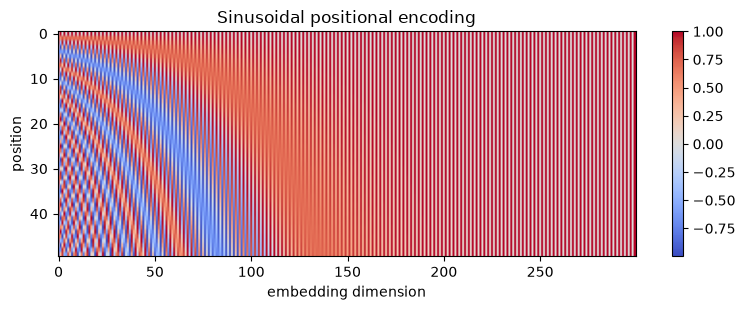

Attention weights (each row sums to 1):
 [[0.682 0.302 0.015]
 [0.291 0.696 0.013]
 [0.5   0.188 0.312]]
Output (weights @ V):
 [[ 1.999 -0.578  0.073 -0.011]
 [ 1.715  0.572  0.116  0.211]
 [ 1.146 -1.069 -0.057  0.026]]


In [10]:
# Demo 1: sinusoidal positional encoding (d = 300, 50 positions)
def sinusoidal_pe(max_pos, d):
    pos = np.arange(max_pos)[:, None]
    i = np.arange(0, d, 2)[None, :]
    angle = pos / np.power(10000.0, i / d)
    pe = np.zeros((max_pos, d))
    pe[:, 0::2] = np.sin(angle)
    pe[:, 1::2] = np.cos(angle)
    return pe

pe = sinusoidal_pe(50, D_MODEL)
fig, ax = plt.subplots(figsize=(8, 3.2))
im = ax.imshow(pe, aspect="auto", cmap="coolwarm")
ax.set_xlabel("embedding dimension"); ax.set_ylabel("position"); ax.set_title("Sinusoidal positional encoding")
plt.colorbar(im); plt.tight_layout(); plt.show()

# Demo 2: scaled dot-product attention on 3 tokens, d_k = 4
rs = np.random.RandomState(0)
Q, K, V = rs.randn(3, 4), rs.randn(3, 4), rs.randn(3, 4)
scores = Q @ K.T / np.sqrt(4)
weights = np.exp(scores) / np.exp(scores).sum(axis=1, keepdims=True)
print("Attention weights (each row sums to 1):\n", np.round(weights, 3))
print("Output (weights @ V):\n", np.round(weights @ V, 3))

## 4. System A — word-level text + FastText wiki vectors

### 4.1 Download the FastText vectors (streamed and truncated)

The official files are `wiki.en.vec` and `wiki.hi.vec` from <https://fasttext.cc/docs/en/pretrained-vectors.html>. They are sorted from the most to the least frequent word and `wiki.en.vec` is ~6 GB, so we **stream** the download and **stop after `FT_MAX_WORDS` lines**. The result is a small `.vec` file in the *word2vec text format* (first line `count dim`, then `word v1 … v300`), which OpenNMT-py reads with `embeddings_type: "word2vec"`.

If the download is blocked on your network, download the two files manually and run `head -n 200001 wiki.en.vec > nmt_lab9/emb/wiki.en.top200000.vec` (same for `hi`) — the notebook will then use them.

In [11]:
import requests

FT_URL = "https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.{lang}.vec"

def fetch_fasttext_top(lang, max_words, out_dir):
    """Stream wiki.<lang>.vec, keep the first `max_words` valid lines, return the path."""
    out_path = os.path.join(out_dir, f"wiki.{lang}.top{max_words}.vec")
    if os.path.exists(out_path) and os.path.getsize(out_path) > 0:
        print(f"  [cached] {out_path}")
        return out_path
    url = FT_URL.format(lang=lang)
    print(f"  streaming {url}  (stops after {max_words:,} words)")
    body_path, kept = out_path + ".body", 0
    try:
        with requests.get(url, stream=True, timeout=60) as r:
            r.raise_for_status()
            lines = r.iter_lines()
            dim = int(next(lines).decode("utf-8").split()[1])          # header: "<count> <dim>"
            with open(body_path, "w", encoding="utf-8") as fout:
                for raw in lines:
                    parts = raw.decode("utf-8", errors="ignore").rstrip().split(" ")
                    if len(parts) != dim + 1 or not parts[0]:
                        continue                                       # skip malformed lines
                    fout.write(" ".join(parts) + "\n")
                    kept += 1
                    if kept % 50_000 == 0:
                        print(f"    ... {kept:,} words")
                    if kept >= max_words:
                        break                                          # closes the connection
        with open(out_path, "w", encoding="utf-8") as fout, open(body_path, encoding="utf-8") as fin:
            fout.write(f"{kept} {dim}\n")
            shutil.copyfileobj(fin, fout)
        os.remove(body_path)
    except Exception as e:
        raise RuntimeError(f"Could not download {url}: {type(e).__name__}: {e}\n"
                           f"Download it manually from https://fasttext.cc/docs/en/pretrained-vectors.html and create "
                           f"{out_path} with:  head -n {max_words + 1} wiki.{lang}.vec > {out_path}")
    print(f"  saved {kept:,} words (dim {dim}) -> {out_path}")
    return out_path

def read_vec_words(path):
    """Set of words in a word2vec-text file (header line skipped)."""
    words = set()
    with open(path, encoding="utf-8") as f:
        next(f)
        for line in f:
            words.add(line.split(" ", 1)[0])
    return words

print("English:")
ft_en_vec = fetch_fasttext_top(SRC_WIKI, FT_MAX_WORDS, EMB_DIR)
print("Hindi:")
ft_hi_vec = fetch_fasttext_top(TGT_WIKI, FT_MAX_WORDS, EMB_DIR)
ft_en_words, ft_hi_words = read_vec_words(ft_en_vec), read_vec_words(ft_hi_vec)
print(f"\nVectors available: English {len(ft_en_words):,} words, Hindi {len(ft_hi_words):,} words")

English:
  streaming https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.en.vec  (stops after 200,000 words)
    ... 50,000 words
    ... 100,000 words
    ... 150,000 words
    ... 200,000 words
  saved 200,000 words (dim 300) -> nmt_lab9/emb/wiki.en.top200000.vec
Hindi:
  streaming https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.hi.vec  (stops after 200,000 words)
    ... 50,000 words
    ... 100,000 words
    ... 150,000 words
  saved 158,016 words (dim 300) -> nmt_lab9/emb/wiki.hi.top200000.vec

Vectors available: English 200,000 words, Hindi 158,016 words


### 4.2 Tokenisation for word-level NMT

A word-level system needs the text split into **tokens that match the tokens in the FastText file**. Rules used:

* Unicode **NFC** normalisation (so the same Devanagari word always has the same code points),
* split on whitespace, then **peel punctuation off the start/end of each word** (`market.` → `market` `.`),
* the Hindi full stop **danda `।`** and double danda `॥` count as punctuation.

> **Why not `\w+`?** In Python, Devanagari vowel signs (matras such as `ा ि ी`) are *not* `\w` characters, so a `\w+` tokenizer would cut Hindi words into pieces. Splitting on whitespace and peeling punctuation avoids that.

**Casing (English).** The fastText file may or may not contain capitalised words. The cell measures how many running English tokens are found with the original casing vs. lower-cased, and lower-cases only if that clearly helps.

In [12]:
PUNCT = set(".,;:!?\"'()[]{}<>-–—…॥।|/\\*&^%$#@~`+=_“”‘’«»")

def nfc(text):
    return unicodedata.normalize("NFC", text)

def tok_ws(text):
    """Whitespace split + peel leading/trailing punctuation. Returns a list of tokens."""
    out = []
    for w in text.split():
        pre, post = [], []
        while w and w[0] in PUNCT:
            pre.append(w[0]); w = w[1:]
        while w and w[-1] in PUNCT:
            post.append(w[-1]); w = w[:-1]
        out.extend(pre)
        if w:
            out.append(w)
        out.extend(reversed(post))
    return out

print(tok_ws(nfc("The cat sat on the mat, (really)!")))
print(tok_ws(nfc("वह बाज़ार गई। उसने कहा, \"ठीक है॥\"")))

['The', 'cat', 'sat', 'on', 'the', 'mat', ',', '(', 'really', ')', '!']
['वह', 'बाज़ार', 'गई', '।', 'उसने', 'कहा', ',', '"', 'ठीक', 'है', '॥', '"']


In [13]:
# decide English casing by measuring coverage in the fastText vocabulary
sample = [t for s, _ in fit_train_pairs[:20000] for t in tok_ws(nfc(s))]
cov_cased = sum(t in ft_en_words for t in sample) / len(sample)
cov_lower = sum(t.lower() in ft_en_words for t in sample) / len(sample)
LOWER_EN = cov_lower > cov_cased + 0.02
print(f"English token coverage in fastText: original case {100*cov_cased:.1f}%   lower-cased {100*cov_lower:.1f}%")
print("=> lower-casing English source text:", LOWER_EN)

def prep_en_ft(s):
    s = nfc(s)
    return tok_ws(s.lower() if LOWER_EN else s)

def prep_hi_ft(s):
    return tok_ws(nfc(s))

def write_aligned(pairs, src_path, tgt_path, src_fn, tgt_fn, keep_empty=False):
    """Write two parallel files (one sentence per line, tokens separated by spaces).
    Training/valid: pairs where either side is empty are dropped.
    Test: nothing is dropped (line i must stay aligned with test_pairs[i])."""
    kept = dropped = 0
    with open(src_path, "w", encoding="utf-8") as fs, open(tgt_path, "w", encoding="utf-8") as ft:
        for s, t in pairs:
            st, tt = src_fn(s), tgt_fn(t)
            if not st or not tt:
                if not keep_empty:
                    dropped += 1
                    continue
                st, tt = st or ["."], tt or ["."]
            fs.write(" ".join(st) + "\n")
            ft.write(" ".join(tt) + "\n")
            kept += 1
    return kept, dropped

for name, pairs, keep in [("train", fit_train_pairs, False), ("valid", valid_pairs, False), ("test", test_pairs, True)]:
    k, d = write_aligned(pairs, f"{FT_DIR}/src-{name}.txt", f"{FT_DIR}/tgt-{name}.txt", prep_en_ft, prep_hi_ft, keep)
    print(f"System A  {name:<6} kept {k:,}  dropped {d}")

print("\nExample (tokenised for System A):")
with open(f"{FT_DIR}/src-test.txt", encoding="utf-8") as f: print("  SRC:", f.readline().strip())
with open(f"{FT_DIR}/tgt-test.txt", encoding="utf-8") as f: print("  TGT:", f.readline().strip())

English token coverage in fastText: original case 86.1%   lower-cased 96.1%
=> lower-casing English source text: True
System A  train  kept 141,632  dropped 0
System A  valid  kept 7,454  dropped 0
System A  test   kept 16,563  dropped 0

Example (tokenised for System A):
  SRC: so , these places up to this point both are 0 .
  TGT: तो , इस पॉइन्ट तक ये दोनों 0 हैं ।


## 5. System B — BPEmb subword encoding + BPEmb vectors

[BPEmb](https://github.com/bheinzerling/bpemb) provides, for 275 languages, a **SentencePiece BPE model** and **pretrained subword embeddings**. Following the repository:

```python
from bpemb import BPEmb
bpemb_en = BPEmb(lang="en", vs=10000, dim=300)
bpemb_en.encode("This is anarchism")   # ['▁this', '▁is', '▁an', 'arch', 'ism']
bpemb_en.decode(['▁this', '▁is', '▁an', 'arch', 'ism'])   # 'this is anarchism'
```

Things to know:

* `encode` first **pre-processes** the text (lower-cases it and replaces every digit by `0`) because that is how the BPE models were trained. So BPEmb output is lower-cased and numbers lose their value — this is a property of BPEmb, and for fairness **we apply the same normalisation to the references before computing BLEU for both systems** (Section 7).
* The source (English) and target (Hindi) each use their own BPEmb model (`en`, `hi`).
* The model **outputs subword pieces**; we `decode` them back to normal text before BLEU.
* The first call downloads the model and vectors from the BPEmb server (~100 MB per language for `dim=300`) into `~/.cache/bpemb`.

In [14]:
from bpemb import BPEmb

bpemb_en = BPEmb(lang=SRC_WIKI, vs=BPE_VS, dim=BPE_DIM)
bpemb_hi = BPEmb(lang=TGT_WIKI, vs=BPE_VS, dim=BPE_DIM)
print(bpemb_en)
print(bpemb_hi)

demo_en = parallel_pairs[0][0]
demo_hi = parallel_pairs[0][1]
print("\nEN text   :", demo_en)
print("EN pieces :", bpemb_en.encode(demo_en))
print("EN decoded:", bpemb_en.decode(bpemb_en.encode(demo_en)))
print("\nHI text   :", demo_hi)
print("HI pieces :", bpemb_hi.encode(demo_hi))
print("HI decoded:", bpemb_hi.decode(bpemb_hi.encode(demo_hi)))

downloading https://nlp.h-its.org/bpemb/en/en.wiki.bpe.vs10000.model


100%|██████████| 400869/400869 [00:00<00:00, 405937.14B/s]


downloading https://nlp.h-its.org/bpemb/en/en.wiki.bpe.vs10000.d300.w2v.bin.tar.gz


100%|██████████| 11189884/11189884 [00:06<00:00, 1774406.68B/s]


downloading https://nlp.h-its.org/bpemb/hi/hi.wiki.bpe.vs10000.model


100%|██████████| 463471/463471 [00:01<00:00, 276744.92B/s]


downloading https://nlp.h-its.org/bpemb/hi/hi.wiki.bpe.vs10000.d300.w2v.bin.tar.gz


100%|██████████| 11215592/11215592 [00:23<00:00, 480763.16B/s] 


BPEmb(lang=en, vs=10000, dim=300)
BPEmb(lang=hi, vs=10000, dim=300)

EN text   : Some countries have declining epidemics, with no reported case in weeks.
EN pieces : ['▁some', '▁countries', '▁have', '▁decl', 'ining', '▁ep', 'id', 'em', 'ics', ',', '▁with', '▁no', '▁reported', '▁case', '▁in', '▁weeks', '.']
EN decoded: some countries have declining epidemics, with no reported case in weeks.

HI text   : कुछ देशों में महामारी घटती जा रही है, जहाँ कई हफ्तों से कोई मामला नहीं है।
HI pieces : ['▁कुछ', '▁देशों', '▁में', '▁महाम', 'ारी', '▁घट', 'ती', '▁जा', '▁रही', '▁है', ',', '▁जहाँ', '▁कई', '▁ह', 'फ्त', 'ों', '▁से', '▁कोई', '▁मामला', '▁नहीं', '▁है', '।']
HI decoded: कुछ देशों में महामारी घटती जा रही है, जहाँ कई हफ्तों से कोई मामला नहीं है।


### 5.1 Export the BPEmb vectors for OpenNMT-py and encode all splits

BPEmb stores its vectors as a gensim `KeyedVectors` object (`bpemb.emb`). `save_word2vec_format(..., binary=False)` writes exactly the *word2vec text format* that OpenNMT-py expects — the "words" are now the subword pieces. Then every split is **encoded into pieces** (one sentence per line, pieces separated by spaces).

In [15]:
bpe_en_vec = f"{EMB_DIR}/bpemb.{SRC_WIKI}.vs{BPE_VS}.d{BPE_DIM}.vec"
bpe_hi_vec = f"{EMB_DIR}/bpemb.{TGT_WIKI}.vs{BPE_VS}.d{BPE_DIM}.vec"
bpemb_en.emb.save_word2vec_format(bpe_en_vec, binary=False)
bpemb_hi.emb.save_word2vec_format(bpe_hi_vec, binary=False)
print("Exported:", bpe_en_vec, "|", bpe_hi_vec)

enc_en = lambda s: bpemb_en.encode(s)
enc_hi = lambda s: bpemb_hi.encode(s)

for name, pairs, keep in [("train", fit_train_pairs, False), ("valid", valid_pairs, False), ("test", test_pairs, True)]:
    k, d = write_aligned(pairs, f"{BPE_DIR}/src-{name}.txt", f"{BPE_DIR}/tgt-{name}.txt", enc_en, enc_hi, keep)
    print(f"System B  {name:<6} kept {k:,}  dropped {d}")

print("\nExample (subword-encoded for System B):")
with open(f"{BPE_DIR}/src-test.txt", encoding="utf-8") as f: print("  SRC:", f.readline().strip())
with open(f"{BPE_DIR}/tgt-test.txt", encoding="utf-8") as f: print("  TGT:", f.readline().strip())

# sequence-length comparison: subwords make sequences longer
def avg_len(path):
    with open(path, encoding="utf-8") as f:
        lens = [len(l.split()) for l in f]
    return sum(lens) / len(lens)
print("\nAverage tokens per sentence (train):")
print(f"  EN  words (A): {avg_len(FT_DIR + '/src-train.txt'):.1f}   pieces (B): {avg_len(BPE_DIR + '/src-train.txt'):.1f}")
print(f"  HI  words (A): {avg_len(FT_DIR + '/tgt-train.txt'):.1f}   pieces (B): {avg_len(BPE_DIR + '/tgt-train.txt'):.1f}")

Exported: nmt_lab9/emb/bpemb.en.vs10000.d300.vec | nmt_lab9/emb/bpemb.hi.vs10000.d300.vec
System B  train  kept 141,632  dropped 0
System B  valid  kept 7,454  dropped 0
System B  test   kept 16,563  dropped 0

Example (subword-encoded for System B):
  SRC: ▁so , ▁these ▁places ▁up ▁to ▁this ▁point ▁both ▁are ▁0.
  TGT: ▁तो , ▁इस ▁पॉ इ न्ट ▁तक ▁ये ▁दोनों ▁0 ▁हैं ।

Average tokens per sentence (train):
  EN  words (A): 19.8   pieces (B): 25.1
  HI  words (A): 21.8   pieces (B): 28.3


## 6. The Transformer training pipeline (shared by both systems)

OpenNMT-py is driven by a **YAML config** and three commands:

| Command | Job |
|---|---|
| `onmt_build_vocab` | counts tokens in the training files and writes the source/target vocabularies |
| `onmt_train` | trains the model; with `src_embeddings` / `tgt_embeddings` set it first **copies the pretrained vectors into the embedding tables** (words missing from the vector file get zeros) |
| `onmt_translate` | translates a file with beam search |

Key config entries:

| Entry | Value | Why |
|---|---|---|
| `encoder_type` / `decoder_type` | `transformer` | the architecture required by the assignment |
| `word_vec_size` = `hidden_size` | 300 | must be equal; = size of the pretrained vectors |
| `heads` | 6 | divides 300 |
| `position_encoding` | `true` | adds the sinusoidal $PE$ |
| `src_embeddings`, `tgt_embeddings`, `embeddings_type: "word2vec"` | the exported `.vec` files | loads FastText / BPEmb vectors (word2vec text format has a 1-line header that is skipped) |
| *(no `freeze_word_vecs_*`)* | – | vectors are **fine-tuned**; zero-initialised unknown/special tokens need to learn |
| `decay_method: noam`, `warmup_steps` | see §3.2 | Transformer learning-rate schedule |
| `label_smoothing` | 0.1 | see §3.2 |
| `batch_type: tokens` | tokens per batch | efficient batching for Transformers |
| `num_workers: 0` | – | avoids data-loader worker crashes on macOS / notebooks |

The helpers call OpenNMT-py as `python -m onmt.bin.<tool>` using **this kernel's Python**, so no PATH problems. Progress lines (`Step …`, `Validation …`) are shown live; the full log is saved next to the model.

In [16]:
KEY_LINES = re.compile(r"Step \d+/|Validation|match|missing|vectors|Saving|Traceback|Error|error", re.I)

def run_onmt(module, args, label, log_path):
    """Run `python -m onmt.bin.<module> <args>`; stream key log lines; raise on failure."""
    cmd = [sys.executable, "-m", f"onmt.bin.{module}"] + [str(a) for a in args]
    print(f"[{label}] " + " ".join(cmd))
    t0, tail = time.time(), collections.deque(maxlen=60)
    with open(log_path, "w", encoding="utf-8") as log:
        proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
        for line in proc.stdout:
            log.write(line); tail.append(line)
            if KEY_LINES.search(line):
                print("   ", line.rstrip()[:200])
        proc.wait()
    if proc.returncode != 0:
        print("".join(tail))
        raise RuntimeError(f"{label} failed (exit code {proc.returncode}); full log: {log_path}")
    print(f"[{label}] finished in {time.time() - t0:.0f}s\n")
    return time.time() - t0


def make_config(tag, data_dir, vocab_size, seq_len, src_emb=None, tgt_emb=None):
    run = f"{WORK_DIR}/{tag}/run"
    os.makedirs(run, exist_ok=True)
    emb_block = ""
    if src_emb and tgt_emb:
        emb_block = (f'src_embeddings: "{src_emb}"\n'
                     f'tgt_embeddings: "{tgt_emb}"\n'
                     f'embeddings_type: "word2vec"\n')
    cfg = f"""
save_data: "{run}/example"
src_vocab: "{run}/example.vocab.src"
tgt_vocab: "{run}/example.vocab.tgt"
overwrite: true
seed: {RANDOM_SEED}

data:
    corpus_1:
        path_src: "{data_dir}/src-train.txt"
        path_tgt: "{data_dir}/tgt-train.txt"
    valid:
        path_src: "{data_dir}/src-valid.txt"
        path_tgt: "{data_dir}/tgt-valid.txt"

src_vocab_size: {vocab_size}
tgt_vocab_size: {vocab_size}
src_seq_length: {seq_len}
tgt_seq_length: {seq_len}
{emb_block}
save_model: "{run}/model"
save_checkpoint_steps: {min(1000, P['train_steps'])}
keep_checkpoint: 2
train_steps: {P['train_steps']}
valid_steps: {P['valid_steps']}
report_every: 50

encoder_type: transformer
decoder_type: transformer
position_encoding: true
enc_layers: {P['layers']}
dec_layers: {P['layers']}
heads: {HEADS}
hidden_size: {D_MODEL}
word_vec_size: {D_MODEL}
transformer_ff: {P['ff']}
dropout: [{DROPOUT}]
attention_dropout: [0.1]
param_init: 0.0
param_init_glorot: true
label_smoothing: 0.1

batch_type: tokens
batch_size: {P['batch_tokens']}
valid_batch_size: 16
bucket_size: 20000
accum_count: [1]
accum_steps: [0]
optim: adam
adam_beta2: 0.998
decay_method: noam
learning_rate: 1.0
warmup_steps: {P['warmup']}
max_grad_norm: 0
normalization: tokens
num_workers: 0
"""
    cfg_path = f"{WORK_DIR}/{tag}/config.yaml"
    with open(cfg_path, "w", encoding="utf-8") as f:
        f.write(cfg)
    return cfg_path, run


def report_vocab_coverage(vocab_path, vec_words, label):
    """How many vocabulary entries (types) / running tokens have a pretrained vector?"""
    entries = []
    with open(vocab_path, encoding="utf-8") as f:
        for line in f:
            parts = line.rstrip("\n").split()
            if not parts:
                continue
            cnt = int(parts[-1]) if len(parts) > 1 and parts[-1].isdigit() else 1
            entries.append((parts[0], cnt))
    types_hit = sum(w in vec_words for w, _ in entries)
    tok_total = sum(c for _, c in entries)
    tok_hit = sum(c for w, c in entries if w in vec_words)
    print(f"   {label}: {types_hit:,}/{len(entries):,} vocab entries have a pretrained vector "
          f"({100*types_hit/len(entries):.1f}% of types, {100*tok_hit/tok_total:.1f}% of running tokens)")
    return {"types": len(entries), "types_hit": types_hit, "tok_cov": tok_hit / tok_total}


def run_system(tag, data_dir, vocab_size, seq_len, src_vec, tgt_vec, postprocess, src_words, tgt_words):
    """Build vocab -> (train) -> translate test set. Returns dict with hypotheses etc."""
    cfg_path, run = make_config(tag, data_dir, vocab_size, seq_len, src_vec, tgt_vec)
    with open(f"{data_dir}/src-train.txt", encoding="utf-8") as f:
        n_train = sum(1 for _ in f)
    run_onmt("build_vocab", ["-config", cfg_path, "-n_sample", n_train], f"{tag}: build vocab", f"{run}/build_vocab.log")
    cov = {"src": report_vocab_coverage(f"{run}/example.vocab.src", src_words, "source (English)"),
           "tgt": report_vocab_coverage(f"{run}/example.vocab.tgt", tgt_words, "target (Hindi)  ")}

    final_model = f"{run}/model_step_{P['train_steps']}.pt"
    train_secs = None
    if os.path.exists(final_model) and not FORCE_RETRAIN:
        print(f"[{tag}] found {final_model} -> skipping training (set FORCE_RETRAIN=True to retrain)\n")
    else:
        train_secs = run_onmt("train", ["-config", cfg_path], f"{tag}: train", f"{run}/train.log")

    pred_path = f"{run}/pred-test.txt"
    run_onmt("translate",
             ["-model", final_model, "-src", f"{data_dir}/src-test.txt", "-output", pred_path,
              "-gpu", "-1", "-batch_size", 32, "-beam_size", 5, "-max_length", 250],
             f"{tag}: translate", f"{run}/translate.log")
    with open(pred_path, encoding="utf-8") as f:
        raw = [line.rstrip("\n") for line in f]
    assert len(raw) == len(test_pairs), f"expected {len(test_pairs)} translations, got {len(raw)}"
    return {"tag": tag, "raw": raw, "hyps": [postprocess(l) for l in raw],
            "coverage": cov, "train_secs": train_secs, "run": run}


def post_ft(line):
    return line.strip()

def post_bpe(line):
    pieces = line.split()
    return bpemb_hi.decode(pieces) if pieces else ""

systems = {}

### 6.1 Train + translate **System A** (FastText, word level)

This builds the vocabulary, **loads the pretrained FastText vectors into the encoder and decoder embedding tables**, trains the Transformer, and translates the test set. Watch the log for the line `… match, … missing` — it tells you how many vocabulary words received a pretrained vector.

In [17]:
systems["FastText"] = run_system(
    tag="fasttext", data_dir=FT_DIR, vocab_size=FT_VOCAB, seq_len=200,
    src_vec=ft_en_vec, tgt_vec=ft_hi_vec, postprocess=post_ft,
    src_words=ft_en_words, tgt_words=ft_hi_words)
print("Example hypothesis:", systems["FastText"]["hyps"][0])

[fasttext: build vocab] /opt/anaconda3/envs/llm_env/bin/python -m onmt.bin.build_vocab -config nmt_lab9/fasttext/config.yaml -n_sample 141632
[fasttext: build vocab] finished in 5s

   source (English): 39,431/77,400 vocab entries have a pretrained vector (50.9% of types, 96.1% of running tokens)
   target (Hindi)  : 44,931/108,018 vocab entries have a pretrained vector (41.6% of types, 93.8% of running tokens)
[fasttext: train] /opt/anaconda3/envs/llm_env/bin/python -m onmt.bin.train -config nmt_lab9/fasttext/config.yaml
    [2026-10-14 19:14:51,821 INFO] Missing transforms field for corpus_1 data, set to default: [].
    [2026-10-14 19:14:51,821 INFO] Missing transforms field for valid data, set to default: [].
    [2026-10-14 19:14:54,159 INFO] 	Found 200000 total vectors in file.
    [2026-10-14 19:14:56,222 INFO] 	Found 158016 total vectors in file
    [2026-10-14 19:14:56,222 INFO] After filtering to vectors in vocab:
    [2026-10-14 19:14:56,227 INFO] 	* enc: 24721 match, 7279 m

### 6.2 Train + translate **System B** (BPEmb, subword level)

Same configuration, but the data are subword pieces and the embeddings come from BPEmb. The model outputs **pieces**; `post_bpe` **decodes** them back into Hindi text with `bpemb_hi.decode`.

In [30]:
# bpe_en_words, bpe_hi_words = read_vec_words(bpe_en_vec), read_vec_words(bpe_hi_vec)
# systems["BPEmb"] = run_system(
#     tag="bpemb", data_dir=BPE_DIR, vocab_size=BPE_VS, seq_len=250,
#     src_vec=bpe_en_vec, tgt_vec=bpe_hi_vec, postprocess=post_bpe,
#     src_words=bpe_en_words, tgt_words=bpe_hi_words)
# print("Example raw output (pieces):", systems["BPEmb"]["raw"][0])
# print("Example decoded            :", systems["BPEmb"]["hyps"][0])
bpe_en_vec = f"{EMB_DIR}/bpemb.{SRC_WIKI}.vs{BPE_VS}.d{BPE_DIM}.vec"
bpe_hi_vec = f"{EMB_DIR}/bpemb.{TGT_WIKI}.vs{BPE_VS}.d{BPE_DIM}.vec"

def has_space(piece):
    return (not piece) or any(ch.isspace() for ch in piece)

def export_vec(kv, path):
    keys = [w for w in kv.index_to_key if not has_space(w)]
    with open(path, "w", encoding="utf-8") as f:
        f.write(f"{len(keys)} {kv.vector_size}\n")
        for w in keys:
            f.write(w + " " + " ".join(f"{x:.5f}" for x in kv.get_vector(w)) + "\n")
    return len(keys)

n1, n2 = export_vec(bpemb_en.emb, bpe_en_vec), export_vec(bpemb_hi.emb, bpe_hi_vec)
print(f"Exported {n1:,} English and {n2:,} Hindi piece vectors.")

def clean_pieces(pieces):
    return [("<unk>" if has_space(p) else p) for p in pieces]

enc_en = lambda s: clean_pieces(bpemb_en.encode(s))
enc_hi = lambda s: clean_pieces(bpemb_hi.encode(s))

for name, pairs, keep in [("train", fit_train_pairs, False), ("valid", valid_pairs, False), ("test", test_pairs, True)]:
    k, d = write_aligned(pairs, f"{BPE_DIR}/src-{name}.txt", f"{BPE_DIR}/tgt-{name}.txt", enc_en, enc_hi, keep)
    print(f"System B  {name:<6} kept {k:,}  dropped {d}")

Exported 10,000 English and 10,000 Hindi piece vectors.
System B  train  kept 141,632  dropped 0
System B  valid  kept 7,454  dropped 0
System B  test   kept 16,563  dropped 0


## 7. Evaluation with sacreBLEU — overall and bin-wise

[sacreBLEU](https://github.com/mjpost/sacrebleu) computes **corpus BLEU** (counts summed over all sentences, then one BLEU number) with a standard, reproducible implementation. We also report **chrF** (character n-gram F-score, which suits morphologically rich Hindi) as a secondary check.

**Scoring protocol — identical for both systems:**

1. Hypotheses and references are put through the **same normalisation**: NFC → lower-case → every digit → `0` (this is BPEmb's own pre-processing, applied to both systems so neither is penalised for it).
2. Both are tokenised with the **same** `tok_ws` (punctuation, including the danda `।`, split off). sacreBLEU's built-in `13a` tokeniser does not split the danda, so we tokenise ourselves and tell sacreBLEU `tokenize="none"`.
3. BLEU is computed on the **whole test set** and **separately for each length bin** (using `test_bin_of`).

> The numbers are *tokenised* BLEU on a normalised text — consistent across the two systems here, but not directly comparable with BLEU reported by others using different tokenisation.

In [31]:
def score_norm(text):
    text = nfc(text).lower()
    text = re.sub(r"\d", "0", text)
    return " ".join(tok_ws(text))

references = [t for _, t in test_pairs]
refs_n = [score_norm(r) for r in references]

bleu_metric = BLEU(tokenize="none")
chrf_metric = CHRF()

def evaluate(hyps, system_name):
    hyps_n = [score_norm(h) for h in hyps]
    groups = [("ALL", list(range(len(refs_n))))] + \
             [(b, [i for i, bb in enumerate(test_bin_of) if bb == b]) for b in BIN_ORDER]
    rows = []
    for name, idx in groups:
        if not idx:
            continue
        h, r = [hyps_n[i] for i in idx], [refs_n[i] for i in idx]
        bl, cf = bleu_metric.corpus_score(h, [r]), chrf_metric.corpus_score(h, [r])
        rows.append({"System": system_name, "Bin": name, "N": len(idx),
                     "BLEU": bl.score, "chrF": cf.score, "BP": bl.bp,
                     "P1": bl.precisions[0], "P4": bl.precisions[3],
                     "len ratio": bl.sys_len / max(1, bl.ref_len)})
    return rows

all_rows = []
for name, s in systems.items():
    all_rows += evaluate(s["hyps"], name)
results_df = pd.DataFrame(all_rows)
print("BLEU signature:", bleu_metric.get_signature())
results_df.round(2)

BLEU signature: nrefs:1|case:mixed|eff:no|tok:none|smooth:exp|version:2.6.0


,System,Bin,N,BLEU,chrF,BP,P1,P4,len ratio
0,FastText,ALL,16563,13.95,31.18,0.96,43.80,5.34,0.96
1,FastText,bin1 (<=10),3337,20.23,36.91,1.00,50.30,8.68,1.00
2,FastText,"bin2 (10,20]",7558,14.77,32.45,0.96,45.10,5.70,0.96
3,FastText,"bin3 (20,30]",3900,12.43,29.72,0.96,41.58,4.52,0.96
4,FastText,bin4 (>30),1768,12.33,28.76,0.93,41.71,4.79,0.93


### 7.1 Bin-wise BLEU table and chart

`ALL` is the overall test-set BLEU. `BP` is the brevity penalty (1.0 = no penalty), `P1`/`P4` are the unigram / 4-gram precisions, `len ratio` = hypothesis length ÷ reference length (below 1 means outputs are too short).

System,N test,FastText
Bin,,
ALL,16563,13.95
bin1 (<=10),3337,20.23
"bin2 (10,20]",7558,14.77
"bin3 (20,30]",3900,12.43
bin4 (>30),1768,12.33


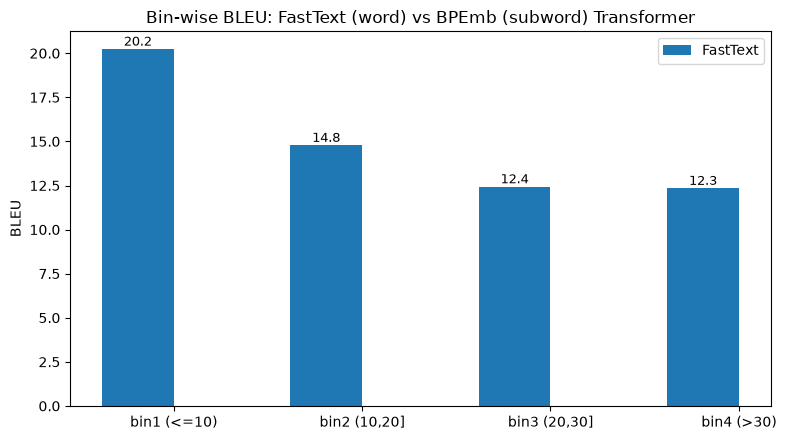

In [32]:
pivot = results_df.pivot(index="Bin", columns="System", values="BLEU").reindex(["ALL"] + BIN_ORDER)
n_per_bin = results_df.drop_duplicates("Bin").set_index("Bin")["N"].reindex(pivot.index)
table = pivot.copy()
table.insert(0, "N test", n_per_bin)
display(table.round(2))

bins_only = pivot.loc[BIN_ORDER]
x = np.arange(len(BIN_ORDER)); w = 0.38
fig, ax = plt.subplots(figsize=(8, 4.5))
for k, sysname in enumerate(bins_only.columns):
    vals = bins_only[sysname].values
    bars = ax.bar(x + (k - 0.5) * w, vals, w, label=sysname)
    for xi, v in zip(x + (k - 0.5) * w, vals):
        ax.text(xi, v + 0.2, f"{v:.1f}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(BIN_ORDER)
ax.set_ylabel("BLEU"); ax.set_title("Bin-wise BLEU: FastText (word) vs BPEmb (subword) Transformer")
ax.legend(); plt.tight_layout(); plt.show()

## 8. Bin-wise result analysis

### 8.1 Diagnostics that help *explain* the numbers

For each bin we measure, on the test set:

* **average English length** (words) and reference length,
* **System A:** share of English test tokens that are **out of vocabulary** (→ `<unk>` at the input) and share of `<unk>` tokens the system **outputs**,
* **System B:** **subword fertility** = pieces per word (more pieces → longer sequences, which the Transformer must attend over),
* the hypothesis/reference **length ratio** (from the table above).

In [33]:
def read_lines(p):
    with open(p, encoding="utf-8") as f:
        return [l.rstrip("\n") for l in f]

def vocab_set(path):
    return {l.split()[0] for l in read_lines(path) if l.split()}

ft_src_vocab = vocab_set(systems["FastText"]["run"] + "/example.vocab.src")
ft_src_test  = [l.split() for l in read_lines(f"{FT_DIR}/src-test.txt")]
bpe_src_test = [l.split() for l in read_lines(f"{BPE_DIR}/src-test.txt")]
bpe_tgt_ref  = [l.split() for l in read_lines(f"{BPE_DIR}/tgt-test.txt")]
ft_raw_hyp   = [l.split() for l in systems["FastText"]["raw"]]

rows = []
for b in BIN_ORDER:
    idx = [i for i, bb in enumerate(test_bin_of) if bb == b]
    if not idx:
        continue
    en_words = np.mean([len(test_pairs[i][0].split()) for i in idx])
    hi_words = np.mean([len(test_pairs[i][1].split()) for i in idx])
    src_tok = [t for i in idx for t in ft_src_test[i]]
    oov = np.mean([t not in ft_src_vocab for t in src_tok]) * 100
    hyp_tok = [t for i in idx for t in ft_raw_hyp[i]]
    unk_out = 100 * sum(t == "<unk>" for t in hyp_tok) / max(1, len(hyp_tok))
    fert_src = sum(len(bpe_src_test[i]) for i in idx) / sum(len(test_pairs[i][0].split()) for i in idx)
    fert_tgt = sum(len(bpe_tgt_ref[i]) for i in idx) / sum(len(test_pairs[i][1].split()) for i in idx)
    rows.append({"Bin": b, "N": len(idx), "avg EN words": en_words, "avg HI ref words": hi_words,
                 "A: EN OOV tokens %": oov, "A: <unk> in output %": unk_out,
                 "B: EN pieces/word": fert_src, "B: HI pieces/word": fert_tgt})
diag_df = pd.DataFrame(rows).set_index("Bin")
display(diag_df.round(2))

len_ratio = results_df[results_df.Bin.isin(BIN_ORDER)].pivot(index="Bin", columns="System", values="len ratio").reindex(BIN_ORDER)
print("Hypothesis / reference length ratio per bin:")
display(len_ratio.round(2))

,N,avg EN words,avg HI ref words,A: EN OOV tokens %,A: <unk> in output %,B: EN pieces/word,B: HI pieces/word
Bin,,,,,,,
bin1 (<=10),3337,7.57,9.22,1.49,4.11,1.43,1.44
"bin2 (10,20]",7558,15.24,16.99,1.29,4.73,1.36,1.38
"bin3 (20,30]",3900,24.63,26.63,1.44,5.89,1.36,1.39
bin4 (>30),1768,38.35,40.83,1.46,5.51,1.34,1.40


Hypothesis / reference length ratio per bin:


System,FastText
Bin,
bin1 (<=10),1.00
"bin2 (10,20]",0.96
"bin3 (20,30]",0.96
bin4 (>30),0.93


### 8.2 Automatic summary of the results

The cell below reads the table and writes plain-English observations (best system per bin, how BLEU changes with length). Use them as the factual base of your written analysis.

In [35]:
names = list(bins_only.columns)
print("Overall BLEU:", ", ".join(f"{n} = {pivot.loc['ALL', n]:.2f}" for n in names))
print()
for b in BIN_ORDER:
    if b not in bins_only.index or bins_only.loc[b].isna().any():
        continue
    if len(names) == 1:
        print(f"{b:<14} {names[0]} BLEU = {bins_only.loc[b, names[0]]:.2f}   N = {int(n_per_bin[b])}")
        continue
    best = bins_only.loc[b].idxmax()
    other = [n for n in names if n != best][0]
    gap = bins_only.loc[b, best] - bins_only.loc[b, other]
    if abs(gap) < 0.05:
        print(f"{b:<14} tie ({names[0]} = {bins_only.loc[b, names[0]]:.2f}, {names[1]} = {bins_only.loc[b, names[1]]:.2f})   N = {int(n_per_bin[b])}")
    else:
        print(f"{b:<14} best: {best:<9} (+{gap:.2f} BLEU over {other})   N = {int(n_per_bin[b])}")

print()
for n in names:
    first, last = bins_only[n].iloc[0], bins_only[n].iloc[-1]
    word = "decreases" if last < first else "increases"
    print(f"{n}: BLEU {word} from {first:.2f} (shortest bin) to {last:.2f} (longest bin).")

if len(names) > 1:
    wins = (bins_only[(bins_only.max(axis=1) - bins_only.min(axis=1)) >= 0.05].idxmax(axis=1).value_counts()).to_dict()
    print("\nBins won:", wins)
else:
    print("\n(Only one system so far - train System B (BPEmb), re-run Section 7, then re-run this cell.)")

Overall BLEU: FastText = 13.95

bin1 (<=10)    FastText BLEU = 20.23   N = 3337
bin2 (10,20]   FastText BLEU = 14.77   N = 7558
bin3 (20,30]   FastText BLEU = 12.43   N = 3900
bin4 (>30)     FastText BLEU = 12.33   N = 1768

FastText: BLEU decreases from 20.23 (shortest bin) to 12.33 (longest bin).

(Only one system so far - train System B (BPEmb), re-run Section 7, then re-run this cell.)


### 8.3 Qualitative examples (one per bin)

Reading real outputs often explains more than the score. Look for untranslated words, `<unk>`, repeated phrases, dropped clauses (too-short output) and wrong word order.

In [36]:
for b in BIN_ORDER:
    idx = [i for i, bb in enumerate(test_bin_of) if bb == b]
    if not idx:
        continue
    i = idx[0]
    print(f"--- {b} ---")
    print("SRC     :", test_pairs[i][0])
    print("REF     :", test_pairs[i][1])
    for n in names:
        print(f"{n:<8}:", systems[n]["hyps"][i])
    print()

--- bin1 (<=10) ---
SRC     : So, these places up to this point both are 0.
REF     : तो, इस पॉइन्ट तक ये दोनों 0 हैं।
FastText: तो , ये दोनों जगहें 0 से 0 तक हैं ।

--- bin2 (10,20] ---
SRC     : If this is not the relevance of a writer , then what else ?
REF     : अगर यह किसी लेखक की प्रासंगिकता नहीं तो और क्या है ?
FastText: यदि यह एक लेखक का जवाब नहीं है , तो क्या ?

--- bin3 (20,30] ---
SRC     : On 8 February 2020, the laboratory OncoGen in Romania published a paper on the design of a vaccine with similar technology to the one used for cancer neoantigen vaccination therapy.
REF     : 8 फरवरी 2020 को रोमानिया में प्रयोगशाला ओन्कोजेन ने कैंसर के नियोएंटीजन टीकाकरण चिकित्सा के लिए इस्तेमाल की जाने वाली तकनीक के समान एक टीके के डिज़ाइन पर एक पेपर प्रकाशित किया।
FastText: 8 फरवरी 2020 के दशक में , <unk> ने एक <unk> के साथ एक <unk> टीका लगाया ।

--- bin4 (>30) ---
SRC     : But in this course we are going to be looking at spider and that is primarily because it is a very good software t

### 8.4 Save the results

In [37]:
results_df.to_csv(f"{WORK_DIR}/bin_wise_bleu.csv", index=False)
diag_df.to_csv(f"{WORK_DIR}/bin_diagnostics.csv")
summary = {"profile": PROFILE, "data_source": DATA_SOURCE, "train_pairs": len(fit_train_pairs),
           "test_pairs": len(test_pairs), "train_steps": P["train_steps"],
           "coverage": {n: s["coverage"] for n, s in systems.items()},
           "train_secs": {n: s["train_secs"] for n, s in systems.items()}}
with open(f"{WORK_DIR}/summary.json", "w") as f:
    json.dump(summary, f, indent=2)
print(f"Saved: {WORK_DIR}/bin_wise_bleu.csv, bin_diagnostics.csv, summary.json")

Saved: nmt_lab9/bin_wise_bleu.csv, bin_diagnostics.csv, summary.json


## 9. Your written analysis (template)

Replace the sentences in *italics* with what **your** tables show. Typical patterns to look for (these are general expectations, **not** guaranteed results — check them against your numbers):

1. **Effect of sentence length.** *BLEU usually falls as sentences get longer (bin1 → bin4): more words to translate, more chances for a wrong word or reordering, and 4-gram matches become rarer. Check whether the length ratio drops below 1 in the long bins (the model stops too early → brevity penalty).*
2. **Short bins** contain short, formulaic ILCI sentences; BLEU there can be high, but with few n-grams per sentence it is also volatile.
3. **FastText (word-level).** *Strengths: short sequences, whole-word vectors. Weaknesses: a closed vocabulary → `<unk>` for rare words and inflected Hindi forms; check the OOV % and `<unk>` % in 8.1, and whether they grow with the bin.*
4. **BPEmb (subword).** *Strengths: no unknown words, shares pieces between related word forms, helps rare/inflected words. Weaknesses: longer sequences (see pieces/word) which can hurt the longest bin, and BPEmb's lower-casing/digit mapping.*
5. **Which embedding wins, and where?** *Use 8.2: name the bins each system wins and the size of the gap versus the noise level (few test sentences per bin).*
6. **Caveats.** *Small training budget (steps), one run per system (no seeds averaged), test sentences that also occur in training (printed in §2.2), tokenised-BLEU protocol.*

### 9.1 Optional: compare with your Lab 8 (RNN) results

Paste your Lab 8 bin-wise BLEU values here to get a side-by-side chart; leave it as `None` to skip.

In [38]:
LAB8_BLEU = None   # e.g. {"bin1 (<=10)": 12.3, "bin2 (10,20]": 9.8, "bin3 (20,30]": 7.1, "bin4 (>30)": 4.0}

if LAB8_BLEU:
    cmp_df = bins_only.copy()
    cmp_df["Lab8 RNN"] = pd.Series(LAB8_BLEU)
    display(cmp_df.round(2))
    cmp_df.plot(kind="bar", figsize=(9, 4.5), rot=0, title="Transformer (FastText / BPEmb) vs Lab 8 RNN")
    plt.ylabel("BLEU"); plt.tight_layout(); plt.show()
else:
    print("LAB8_BLEU not set - skipping.")

LAB8_BLEU not set - skipping.


## 10. Troubleshooting

| Symptom | Fix |
|---|---|
| `Library not loaded: @rpath/libOpenNMTTokenizer.dylib` | `python -m pip install --no-cache-dir --force-reinstall "pyonmttok==1.37.1"`, restart kernel |
| `Cannot access gated repo` / BPCC fails to load | accept the terms on the BPCC dataset page and `huggingface-cli login` |
| fastText download blocked | download `wiki.en.vec`, `wiki.hi.vec` manually and create the `top200000` files as shown in §4.1 |
| BPEmb download slow / blocked | the first `BPEmb(...)` call downloads into `~/.cache/bpemb`; retry or copy the files there |
| Training too slow | use `PROFILE = "fast"`, or lower `max_train` / `layers` |
| Out-of-memory | lower `batch_tokens` in the profile |
| Loss becomes `nan` | lower `learning_rate` in `make_config` (e.g. 0.5) |
| Want to retrain with new settings | set `FORCE_RETRAIN = True` |
| `numpy` / `torch` import errors | `%pip install "numpy<2"` and restart the kernel |

**Summary.** Two Transformer NMT systems — identical except for the embeddings/tokenisation (FastText words vs BPEmb subwords) — were trained with OpenNMT-py on BPCC `ilci` English→Hindi, evaluated with sacreBLEU overall and per length bin, and compared in Section 8.